In [1]:
from scipy.signal import firwin
import numpy as np

fs = 20

coef = firwin(
    256,
    [0.1,0.5],
    pass_zero='bandpass',
    fs=fs
)

In [2]:
print(f'{coef}')

[ 3.36411873e-04  3.21106930e-04  3.02116156e-04  2.79512760e-04
  2.53399360e-04  2.23919200e-04  1.91269225e-04  1.55714119e-04
  1.17600289e-04  7.73686956e-05  3.55653612e-05 -7.15153946e-06
 -5.00090806e-05 -9.21223867e-05 -1.32503575e-04 -1.70077341e-04
 -2.03703431e-04 -2.32205917e-04 -2.54408905e-04 -2.69177934e-04
 -2.75466047e-04 -2.72363160e-04 -2.59147113e-04 -2.35334562e-04
 -2.00729663e-04 -1.55468442e-04 -1.00056676e-04 -3.53991786e-05
  3.71814765e-05  1.15938553e-04  1.98708525e-04  2.82933296e-04
  3.65697901e-04  4.43783826e-04  5.13737539e-04  5.71953274e-04
  6.14768522e-04  6.38570154e-04  6.39908557e-04  6.15616713e-04
  5.62930738e-04  4.79608116e-04  3.64039636e-04  2.15350977e-04
  3.34899110e-05 -1.80704698e-04 -4.25455646e-04 -6.98024972e-04
 -9.94718875e-04 -1.31092181e-03 -1.64116080e-03 -1.97920016e-03
 -2.31816586e-03 -2.65069791e-03 -2.96912801e-03 -3.26567909e-03
 -3.53268199e-03 -3.76280442e-03 -3.94928594e-03 -4.08617270e-03
 -4.16854515e-03 -4.19273

In [3]:
print(np.sum(coef))

0.05886120040794429


Text(0, 0.5, 'dB')

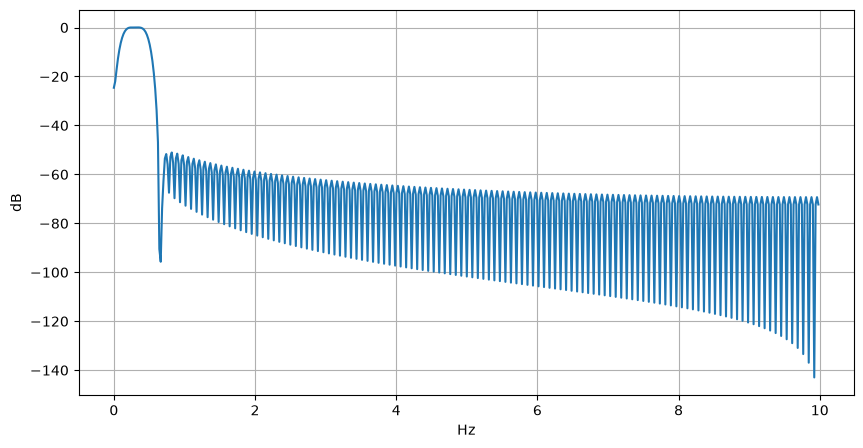

In [4]:
from scipy.signal import freqz
import matplotlib.pyplot as plt

w,H = freqz(coef)

plt.figure(figsize=(10,5))

plt.plot(w*fs/(2*np.pi),
         20*np.log10(np.abs(H)))

plt.grid()

plt.xlabel("Hz")

plt.ylabel("dB")

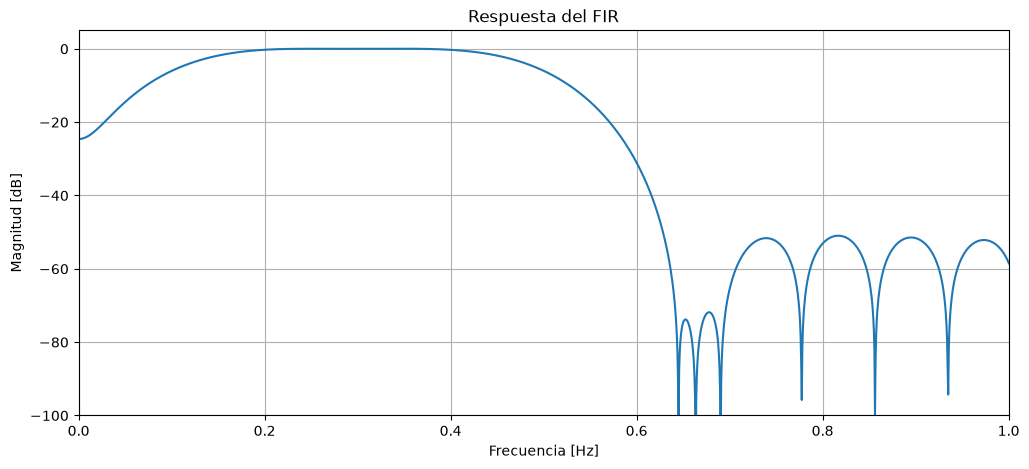

In [5]:
from scipy.signal import freqz
import matplotlib.pyplot as plt
import numpy as np

w, H = freqz(coef, worN=16384)

f = w * fs / (2*np.pi)

plt.figure(figsize=(12,5))

plt.plot(f,20*np.log10(np.abs(H)+1e-12))

plt.xlim(0,1)          # Solo mirar hasta 1 Hz
plt.ylim(-100,5)

plt.grid()

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud [dB]")
plt.title("Respuesta del FIR")

plt.show()

Text(0, 0.5, 'Magnitud [dB]')

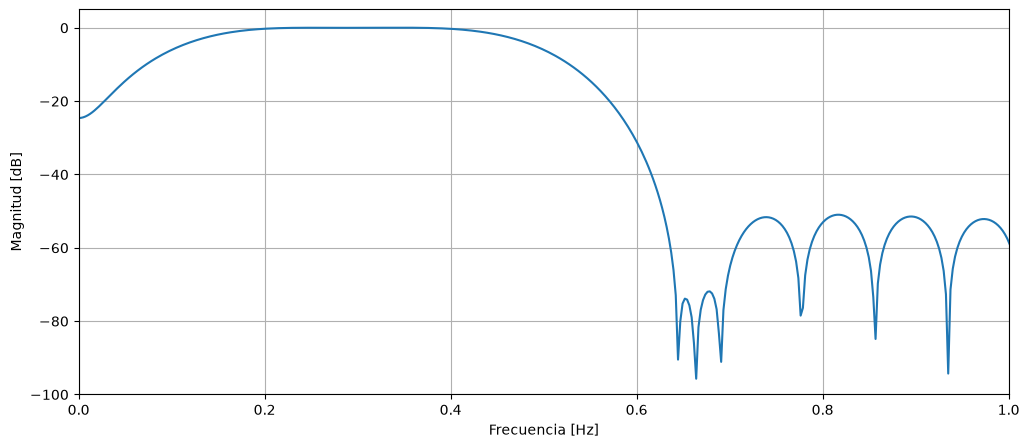

In [6]:
H = np.fft.fft(coef,8192)

f = np.fft.fftfreq(8192,1/fs)

idx = f >= 0

plt.figure(figsize=(12,5))

plt.plot(f[idx],20*np.log10(np.abs(H[idx])+1e-12))

plt.xlim(0,1)

plt.ylim(-100,5)

plt.grid()

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud [dB]")

22
-267
00016 : h(0)
00015 : h(1)
00013 : h(2)
00012 : h(3)
00010 : h(4)
0000E : h(5)
0000C : h(6)
0000A : h(7)
00007 : h(8)
00005 : h(9)
00002 : h(10)
3FFFF : h(11)
3FFFC : h(12)
3FFF9 : h(13)
3FFF7 : h(14)
3FFF4 : h(15)
3FFF2 : h(16)
3FFF0 : h(17)
3FFEF : h(18)
3FFEE : h(19)
3FFED : h(20)
3FFEE : h(21)
3FFEF : h(22)
3FFF0 : h(23)
3FFF2 : h(24)
3FFF5 : h(25)
3FFF9 : h(26)
3FFFD : h(27)
00002 : h(28)
00007 : h(29)
0000D : h(30)
00012 : h(31)
00017 : h(32)
0001D : h(33)
00021 : h(34)
00025 : h(35)
00028 : h(36)
00029 : h(37)
00029 : h(38)
00028 : h(39)
00024 : h(40)
0001F : h(41)
00017 : h(42)
0000E : h(43)
00002 : h(44)
3FFF4 : h(45)
3FFE4 : h(46)
3FFD2 : h(47)
3FFBE : h(48)
3FFAA : h(49)
3FF94 : h(50)
3FF7E : h(51)
3FF68 : h(52)
3FF52 : h(53)
3FF3D : h(54)
3FF29 : h(55)
3FF18 : h(56)
3FF09 : h(57)
3FEFD : h(58)
3FEF4 : h(59)
3FEEE : h(60)
3FEED : h(61)
3FEEF : h(62)
3FEF5 : h(63)
3FF00 : h(64)
3FF0E : h(65)
3FF1F : h(66)
3FF34 : h(67)
3FF4B : h(68)
3FF63 : h(69)
3FF7D : h(70)
3FF97 : 

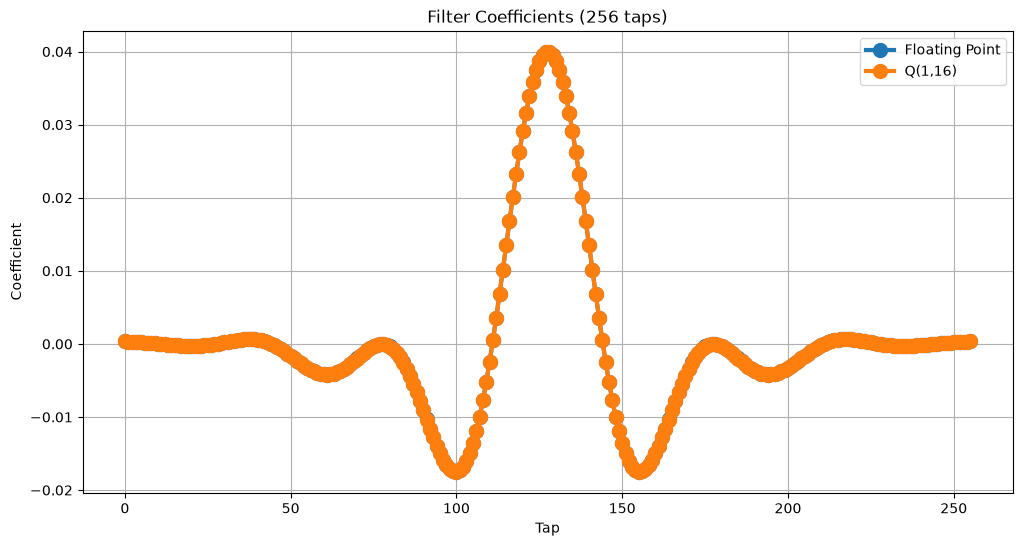

Error máximo : 1.5194833048817052e-05
Error medio  : 7.362820502223705e-06
Error RMS    : 8.615002691819688e-06


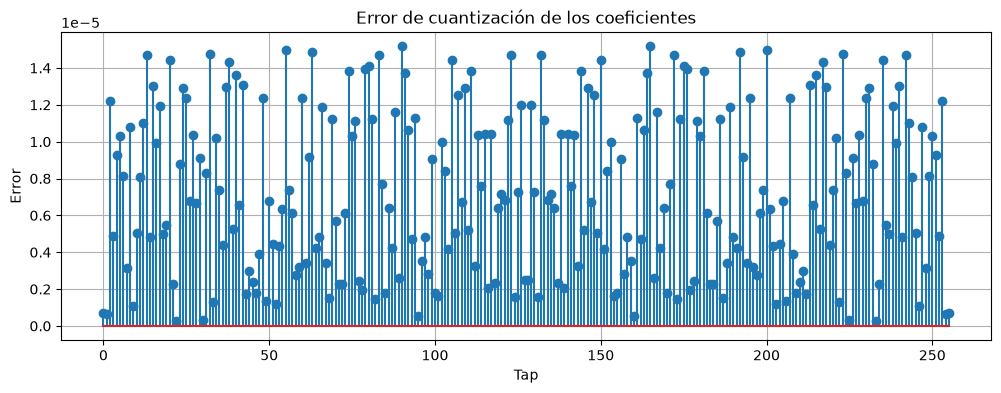

In [7]:
from tool._fixedInt import *

# =====================================================
# Parámetros Q(1,16)
# =====================================================

INT_BITS = 18
FRAC_BITS = 16

# =====================================================
# Coeficientes FIR cuantizados
# =====================================================

coeff = arrayFixedInt(INT_BITS, FRAC_BITS, coef)

coef_int = [c.value for c in coeff]

print(f'{coef_int[0]}')
print(f'{coef_int[63]}')

with open("coeff.mem","w") as f:
    count = 0
    for c in coef_int:
        

        if c < 0:
            c = (1<<18) + c      # complemento a dos
        print(f'{c:05X} : h({count})')
        f.write(f"{c:05X}\n")
        count = count + 1


coeff_fixed = np.array([c.fValue for c in coeff])

# ============================================
# Coeficientes originales
# ============================================

coeff_float = np.array(coef)

# ============================================
# Coeficientes cuantizados
# ============================================

coeff_fixed = np.array([c.fValue for c in coeff])


# ============================================
# Gráfico
# ============================================

plt.figure(figsize=(12,6))

plt.plot(coeff_float,
         '-o',
         linewidth=3,
         markersize=10,
         label='Floating Point')

plt.plot(coeff_fixed,
         '-o',
         linewidth=3,
         markersize=10,
         label='Q(1,16)')

plt.grid(True)

plt.title(f'Filter Coefficients ({len(coeff_float)} taps)')

plt.xlabel('Tap')

plt.ylabel('Coefficient')

plt.legend()

plt.show()

error = coeff_float - coeff_fixed

print("Error máximo :", np.max(np.abs(error)))
print("Error medio  :", np.mean(np.abs(error)))
print("Error RMS    :", np.sqrt(np.mean(error**2)))

plt.figure(figsize=(12,4))

plt.stem(error)

plt.grid(True)

plt.xlabel("Tap")

plt.ylabel("Error")

plt.title("Error de cuantización de los coeficientes")

plt.show()